# Lab 3


In [15]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyreadr
import sys
from sklearn.cluster import KMeans
from numba import njit
import os

from joblib import Parallel, delayed, parallel_config

# same random numbers every time we run this, so results don't change
rng = np.random.default_rng(215)

# Introduction (the data)

The introduction describes the data: 45,152 people and 468 binary columns, where each column is one answer option to one question (1 if they picked it, 0 if not).<br> The file also has some columns we don't want to cluster on, like ID, city, state, and latitude/longitude, so we only keep the columns that are all 0s and 1s.

In [ ]:
# load_binary_ling function but just the 

def load_binary_ling(path):
    """Load lingBinary.Rdata and keep only the 0/1 answer columns."""
    rdata = pyreadr.read_r(path) 
    # grab the dictionary called "lingBinary". 
    frame = rdata["lingBinary"] 
    # keep only columns that are all 0s and 1s (drops ID, city, state, zip, lat, long)
    binary_cols = [col for col in frame.columns
                   if frame[col].notna().all() and frame[col].isin([0, 1]).all()]
    return frame[binary_cols].to_numpy(dtype=np.float64)


# this notebook lives in lab3/code, so the data is one folder up
lingdata = load_binary_ling("../data/lingBinary.Rdata")
print("binary data:", lingdata.shape)  # (number of people, number of answer columns)

binary data: (45152, 468)


Similarity:  Choice of similarity measure (Jaccard)

A clustering gives labels, one per person.


Jaccard looks at pairs of people. For each pair, we ask whether they were together in clustering 1, and whether they were together in clustering 2. 

$$J = \frac{\text{pairs together in both}}{\text{pairs together in at least one}}.$$


In [ ]:
# Fix m and k for now
m = 0.8   
k = 3    
B_val = 5  
i = 1   # which repeat this is (1 to B_val)

#total number of people
n_people = lingdata.shape[0]
#people per subgroup
n_sub = int(round(m * n_people))

#Each k gets a different seed per subgroup
# Ensures clusters arent the same both times
pass_seed = 215 + 2 * (k * B_val + i - 1)
rng = np.random.default_rng(pass_seed)

# subgroup 1 and subgroup 2: two random sets of people
subgroup1 = np.sort(rng.choice(n_people, size=n_sub, replace=False))
subgroup2 = np.sort(rng.choice(n_people, size=n_sub, replace=False))

In [ ]:
# Get k-means for each subgroup

# k-means on each subgroup separately, put initial guess in center of cluster
kmeans_labels1 = KMeans(n_clusters=k, init="k-means++", n_init=1,
                        random_state=1).fit_predict(lingdata[subgroup1])
kmeans_labels2 = KMeans(n_clusters=k, init="k-means++", n_init=1,
                        random_state=2).fit_predict(lingdata[subgroup2])

print("labels from subgroup 1:", len(kmeans_labels1), "people, first 10:", kmeans_labels1[:10])

labels from subgroup 1: 36122 people, first 10: [0 1 1 1 1 2 1 1 0 1]


In [ ]:
# Find numbe rof people in both subgroups
# Count where each sits in subgroups 1 and 2

intersect, pos1, pos2 = np.intersect1d(subgroup1, subgroup2,
                                       assume_unique=True, return_indices=True)

# Create membership vectors, which track which group each ith person
# was put into by the kmeans 
# membership1[x] and membership2[x] are the same person's two labels.
membership1 = kmeans_labels1[pos1]
membership2 = kmeans_labels2[pos2]

q = len(membership1)
print("q =", q)  # about 28,900 shared people
print("membership1, first 10:", membership1[:20])
print("membership2, first 10:", membership2[:20])

q = 28887
membership1, first 10: [0 1 1 2 1 1 0 1 0 0 1 2 0 1 0 0 1 0 0 0]
membership2, first 10: [2 0 0 1 0 0 2 0 2 2 0 1 2 0 2 2 0 2 2 2]


Person 1 was grouped into cluster 2 both times,<br>
Person 2 was grouped into cluster 1 the first time and cluster 0 the second time, <br>
Person 3 was grouped into cluster 1 the first time and cluster 0 the second time, etc.

In [ ]:
# Get similarity function (This is the inefficient version, will not run!)

# # Make sure both vectors describe the same people
# if len(membership1) != len(membership2):
#     raise ValueError("Membership vectors must have the same length.")

# # Checking every pair (inefficient)
# q = len(membership1)

# #Initialize counts of people in N11, N10, and N01
# together_both = 0
# together_first = 0
# together_second = 0
# for a in range(q):
#     for b in range(a + 1, q):
#         same1 = membership1[a] == membership1[b]
#         same2 = membership2[a] == membership2[b]
#         together_first += same1
#         together_second += same2
#         together_both += same1 and same2

# at_least_one = together_first + together_second - together_both
# at_least_one

Lets make a more efficient way to go through these.<br>

You can use a combinatorics trick to go through the pairs more quickly.
A group of n people has (n given 2) =  n * (n - 1)/2 pairs. This helps with the computation

In [ ]:
# Jaccard for every k from 2 to 10, efficient algorithm with combinatorics

# Initialize set of one jaccard score per cluster amount k
jaccard_by_k = {}

# Begin loop over every k
for k in range(2, 11):
    #track time
    start = time.perf_counter()

    # Same as before
    kmeans_labels1 = KMeans(n_clusters=k, init="k-means++", n_init=1,
                            random_state=1).fit_predict(lingdata[subgroup1])
    kmeans_labels2 = KMeans(n_clusters=k, init="k-means++", n_init=1,
                            random_state=2).fit_predict(lingdata[subgroup2])

    # Same as before
    membership1 = kmeans_labels1[pos1]
    membership2 = kmeans_labels2[pos2]

    #Number shared people in subgroups
    q = len(membership1)

    # Nubmer of rows needed
    k1 = membership1.max() + 1
    k2 = membership2.max() + 1

    # Initialize table that stores one row per cluster
    counts = np.zeros((k1, k2), dtype=np.int64)

    #Loop through each shared person one time
    # Each person adds 1 to the table for their run 1 and run 2 clusters
    # The positions of the cells correspond to the cluster numbers
    for i in range(q):
        counts[membership1[i], membership2[i]] += 1

    # Determine how many per cluster
    # Row totals are cluster assignments from run 1 
    # Column totals are clustter assignments from run 2
    sizes1 = counts.sum(axis=1)
    sizes2 = counts.sum(axis=0)

    # Count the pairs
    # A group of n people has n * (n - 1) // 2 pairs,
    # So look at the counts (shared clusters in both runs)
    # sizes1 (shared clusters in run 1, not run 2)
    # sizes 2 (shared clusters in run 2 but not run 1)
    together_both = (counts * (counts - 1) // 2).sum()
    together_first = (sizes1 * (sizes1 - 1) // 2).sum() 
    together_second = (sizes2 * (sizes2 - 1) // 2).sum()  

    # Apply Jaccard Formula = together in both / together in at least one
    at_least_one = together_first + together_second - together_both
    jaccard = together_both / at_least_one if at_least_one else 1.0
    jaccard_by_k[k] = jaccard

    print(f"k = {k:2d}: Jaccard = {jaccard:.3f}  (q = {q:,}, {time.perf_counter() - start:.1f} s)")

jaccard_by_k

k =  2: Jaccard = 0.580  (q = 28,887, 0.9 s)
k =  3: Jaccard = 0.985  (q = 28,887, 1.4 s)
k =  4: Jaccard = 0.441  (q = 28,887, 1.2 s)
k =  5: Jaccard = 0.675  (q = 28,887, 1.7 s)
k =  6: Jaccard = 0.437  (q = 28,887, 2.0 s)
k =  7: Jaccard = 0.327  (q = 28,887, 2.0 s)
k =  8: Jaccard = 0.321  (q = 28,887, 3.6 s)
k =  9: Jaccard = 0.309  (q = 28,887, 3.2 s)
k = 10: Jaccard = 0.282  (q = 28,887, 2.8 s)


{2: np.float64(0.5803318441140807),
 3: np.float64(0.9850191156093094),
 4: np.float64(0.44130306730355157),
 5: np.float64(0.6745722679703203),
 6: np.float64(0.4371952855652783),
 7: np.float64(0.3271924836125733),
 8: np.float64(0.32145475530459455),
 9: np.float64(0.30856686948131057),
 10: np.float64(0.282098395556662)}

Plain Python loops are slow because Python double-checks everything on every step. Numba makes things a little faster, use `@njit`

In [22]:
@njit
def count_table(membership1, membership2, k1, k2):
    # Each person adds 1 to the table for their run 1 and run 2 clusters
    counts = np.zeros((k1, k2), dtype=np.int64)
    for i in range(len(membership1)):
        counts[membership1[i], membership2[i]] += 1
    return counts

# Same as last, comments removed, besides for change
def jaccard_by_k(data, subgroup1, subgroup2, pos1, pos2, k_values=range(2, 11)):
    jaccard_scores = {}

    for k in k_values:
        start = time.perf_counter()

        kmeans_labels1 = KMeans(n_clusters=k, init="k-means++", n_init=1,
                                random_state=1).fit_predict(data[subgroup1])
        kmeans_labels2 = KMeans(n_clusters=k, init="k-means++", n_init=1,
                                random_state=2).fit_predict(data[subgroup2])

        membership1 = kmeans_labels1[pos1]
        membership2 = kmeans_labels2[pos2]
        q = len(membership1)

        k1 = membership1.max() + 1
        k2 = membership2.max() + 1

        # Numba-compiled counting loop
        counts = count_table(membership1, membership2, k1, k2)

        sizes1 = counts.sum(axis=1)
        sizes2 = counts.sum(axis=0)

        together_both = (counts * (counts - 1) // 2).sum()
        together_first = (sizes1 * (sizes1 - 1) // 2).sum()
        together_second = (sizes2 * (sizes2 - 1) // 2).sum()

        at_least_one = together_first + together_second - together_both
        jaccard = together_both / at_least_one if at_least_one else 1.0
        jaccard_scores[k] = jaccard

        print(f"k = {k:2d}: Jaccard = {jaccard:.3f}  (q = {q:,}, {time.perf_counter() - start:.1f} s)")

    return jaccard_scores


jaccard_scores = jaccard_by_k(lingdata, subgroup1, subgroup2, pos1, pos2)
jaccard_scores

k =  2: Jaccard = 0.580  (q = 28,887, 1.0 s)
k =  3: Jaccard = 0.985  (q = 28,887, 1.0 s)
k =  4: Jaccard = 0.441  (q = 28,887, 1.8 s)
k =  5: Jaccard = 0.675  (q = 28,887, 2.1 s)
k =  6: Jaccard = 0.437  (q = 28,887, 1.7 s)
k =  7: Jaccard = 0.327  (q = 28,887, 2.5 s)
k =  8: Jaccard = 0.321  (q = 28,887, 2.9 s)
k =  9: Jaccard = 0.309  (q = 28,887, 3.1 s)
k = 10: Jaccard = 0.282  (q = 28,887, 2.7 s)


{2: np.float64(0.5803318441140807),
 3: np.float64(0.9850191156093094),
 4: np.float64(0.44130306730355157),
 5: np.float64(0.6745722679703203),
 6: np.float64(0.4371952855652783),
 7: np.float64(0.3271924836125733),
 8: np.float64(0.32145475530459455),
 9: np.float64(0.30856686948131057),
 10: np.float64(0.282098395556662)}

Make a function that takes two membership vectors and returns one number. Loops compiled by Numba. It never builds the $q \times q$ matrix, and it runs in $O(q + k_1 k_2)$ time.

In [ ]:
@njit
def _jaccard(mem1, mem2):
    """Numba-compiled Jaccard score between two membership vectors."""
    # Number of clusters in each run (labels go 0, 1, ..., so max + 1)
    # These are the number of rows and columns in the table
    k1 = mem1.max() + 1
    k2 = mem2.max() + 1

    # Initialize table with one row per run 1 cluster and one column per run 2 cluster
    # counts[cluster1, cluster2] = number of people in cluster1 in run 1 and cluster2 in run 2
    counts = np.zeros((k1, k2), dtype=np.int64)

    # Loop through each shared person one time
    # Each person adds 1 to the cell for their run 1 and run 2 clusters
    for i in range(mem1.shape[0]):
        counts[mem1[i], mem2[i]] += 1

    # Initialize pair counts
    together_both = 0    # pairs in the same cluster in both runs
    together_first = 0   # pairs in the same cluster in run 1
    together_second = 0  # pairs in the same cluster in run 2

    # Go through the table one row (run 1 cluster) at a time
    for cluster1 in range(k1):
        # Running total of people in run 1's cluster1
        row_total = 0
        for cluster2 in range(k2):
            # Number of people in cluster1 in run 1 AND cluster2 in run 2
            people_in_cell = counts[cluster1, cluster2]
            # A group of n people has n * (n - 1) // 2 pairs, all together in both runs
            together_both += people_in_cell * (people_in_cell - 1) // 2
            row_total += people_in_cell
        # row_total = size of run 1's cluster1, so add its pairs
        together_first += row_total * (row_total - 1) // 2

    # Go through the table one column (run 2 cluster) at a time
    for cluster2 in range(k2):
        # Running total of people in run 2's cluster2
        col_total = 0
        for cluster1 in range(k1):
            col_total += counts[cluster1, cluster2]
        # col_total = size of run 2's cluster2, so add its pairs
        together_second += col_total * (col_total - 1) // 2

    # Pairs together in at least one run
    # (subtract together_both because those pairs were counted in both totals)
    at_least_one = together_first + together_second - together_both

    # If no pair is ever together (every cluster has 1 person), call it a perfect match
    if at_least_one == 0:
        return 1.0

    # Jaccard formula = together in both / together in at least one
    return together_both / at_least_one


def similarity(mem1, mem2):
    """Jaccard similarity between two membership vectors.
        mem1, membership1, cluster label of each shared point in run 1
        mem2, membership2, cluster label of the same points in run 2
    """
    mem1 = np.asarray(mem1, dtype=np.int64)
    mem2 = np.asarray(mem2, dtype=np.int64)
    if mem1.shape != mem2.shape:
        raise ValueError("Membership vectors must have the same length.")
    return _jaccard(mem1, mem2)

How fast is it for different $m$? <br>

For each m, cluster two subsamples with k = 10 and time similarity function on the shared people. 

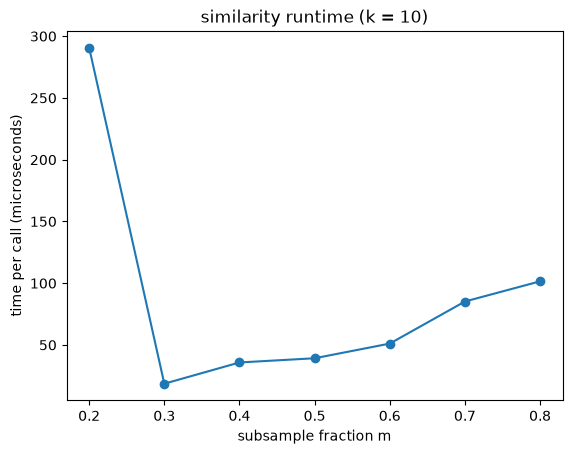

,m,q,microseconds
0,0.2,1814,290.7
1,0.3,4023,18.6
2,0.4,7237,35.8
3,0.5,11231,39.2
4,0.6,16331,51.1
5,0.7,22142,85.2
6,0.8,28882,101.5


In [ ]:
def average_seconds(func, a, b, repeats):
    """Run func(a, b) many times and return the average time per call."""
    # Start the stopwatch (time in seconds)
    start = time.perf_counter()
    # One call is too fast to time accurately,
    #Loop through many and take average
    for _ in range(repeats):
        func(a, b)
    # Total time divided by number of calls = average time for one call
    return (time.perf_counter() - start) / repeats


# Subsample fractions to test (the lab allows m between 0.2 and 0.8)
m_values = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
# Initialize lists to store the number of shared people and the time for each m
q_values = []
microseconds = []

# Begin loop over every m
for m_try in m_values:
    # People per subgroup for this m
    n_try = int(round(m_try * n_people))

    # Two random subgroups of people, same as before
    sub1 = np.sort(rng.choice(n_people, size=n_try, replace=False))
    sub2 = np.sort(rng.choice(n_people, size=n_try, replace=False))

    # k-means on each subgroup, k = 10 as max k
    lab1 = KMeans(n_clusters=10, n_init=1, random_state=1).fit_predict(lingdata[sub1])
    lab2 = KMeans(n_clusters=10, n_init=1, random_state=2).fit_predict(lingdata[sub2])

    # Find the people in both subgroups, and where each sits in subgroups 1 and 2
    _, p1, p2 = np.intersect1d(sub1, sub2, assume_unique=True, return_indices=True)

    # Number of shared people (q), which grows as m grows
    q_values.append(len(p1))

    # Time similarity on the membership vectors (lab1[p1], lab2[p2]),
    # averaged over 1000 calls, and * 1e6 converts seconds to microseconds
    microseconds.append(average_seconds(similarity, lab1[p1], lab2[p2], 1000) * 1e6)

# Plot runtime against m
plt.plot(m_values, microseconds, "o-")
plt.xlabel("subsample fraction m")
plt.ylabel("time per call (microseconds)")
plt.title("similarity runtime (k = 10)")
plt.show()

# Table of m, number of shared people q, and average time per call
pd.DataFrame({"m": m_values, "q": q_values, "microseconds": microseconds}).round(1)

kmeans_stability.py immplementation

For every k from 2 to 10 and every repeat i from 1 to B: draw two new subsamples, run k-means on each, and compute  similarity on the shared people. Similarity_onepair does one (k, i) step.

Every pass is independent, so joblib runs them in parallel. Here B = 5 so it's quick. kmeans_stability.py is the same code with B = 100, SCF with sbatch run.sh, and it saves results/S.csv.

In [25]:
def similarity_onepair(X, k, m, seed, n_init=1):
    """One (k, i) pass of Algorithm 1: returns the similarity of two subsample clusterings."""
    rng = np.random.default_rng(seed)
    n_people = X.shape[0]
    n_sub = int(round(m * n_people))

    subgroup1 = np.sort(rng.choice(n_people, size=n_sub, replace=False))
    subgroup2 = np.sort(rng.choice(n_people, size=n_sub, replace=False))

    kmeans_labels1 = KMeans(n_clusters=k, init="k-means++", n_init=n_init,
                            random_state=seed).fit_predict(X[subgroup1])
    kmeans_labels2 = KMeans(n_clusters=k, init="k-means++", n_init=n_init,
                            random_state=seed + 1).fit_predict(X[subgroup2])

    # Find the people in both subgroups.
    # pos1 = where each shared person sits in subgroup1, pos2 = where they sit in subgroup2,
    # so kmeans_labels1[pos1] and kmeans_labels2[pos2] line up person by person.
    # The _ is the list of shared people's IDs, which we don't need.
    # assume_unique=True: no one appears twice in a subgroup, so this runs faster.
    _, pos1, pos2 = np.intersect1d(subgroup1, subgroup2,
                                   assume_unique=True, return_indices=True)
    return similarity(kmeans_labels1[pos1], kmeans_labels2[pos2])

In [26]:
X = lingdata
m = 0.8
B = 5 # for our example, will be 100 in function
k_max = 10
base_seed = 215
n_init = 1
n_jobs = -1  # use every core

jobs = [(k, i) for k in range(2, k_max + 1) for i in range(1, B + 1)]

# tell joblib: each worker gets 1 thread for its k-means,
# since joblib itself is already using all the cores
with parallel_config(backend="loky", inner_max_num_threads=1):
    results = Parallel(n_jobs=n_jobs, verbose=5)(
        delayed(similarity_onepair)(X, k, m, base_seed + 2 * (k * B + i - 1), n_init)
        for k, i in jobs
    )

# one row per repeat i, one column per k
S = pd.DataFrame(np.array(results).reshape(k_max - 1, B).T,
                 index=pd.RangeIndex(1, B + 1, name="i"),
                 columns=range(2, k_max + 1))
S

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 22 concurrent workers.
[Parallel(n_jobs=-1)]: Done  12 out of  45 | elapsed:   35.6s remaining:  1.6min
[Parallel(n_jobs=-1)]: Done  22 out of  45 | elapsed:   46.6s remaining:   48.8s
[Parallel(n_jobs=-1)]: Done  32 out of  45 | elapsed:   53.4s remaining:   21.6s
[Parallel(n_jobs=-1)]: Done  42 out of  45 | elapsed:   58.9s remaining:    4.1s
[Parallel(n_jobs=-1)]: Done  45 out of  45 | elapsed:  1.0min finished


,2,3,4,5,6,7,8,9,10
i,,,,,,,,,
1,0.758319,0.924743,0.751487,0.559439,0.342683,0.289806,0.462887,0.448180,0.336737
2,0.347022,0.983523,0.826791,0.587641,0.388711,0.293204,0.306561,0.285551,0.457600
3,0.994278,0.981672,0.849609,0.787571,0.423433,0.397683,0.366307,0.441345,0.262461
4,0.567698,0.924769,0.492481,0.425201,0.394984,0.480353,0.347863,0.344736,0.368088
5,0.775394,0.920738,0.820594,0.605510,0.413584,0.329885,0.337226,0.344879,0.386144


# Result

Like Figure 3 of Ben-Hur et al.: the cumulative distribution of the similarities for each $k$. A stable $k$ has its similarities bunched near 1.


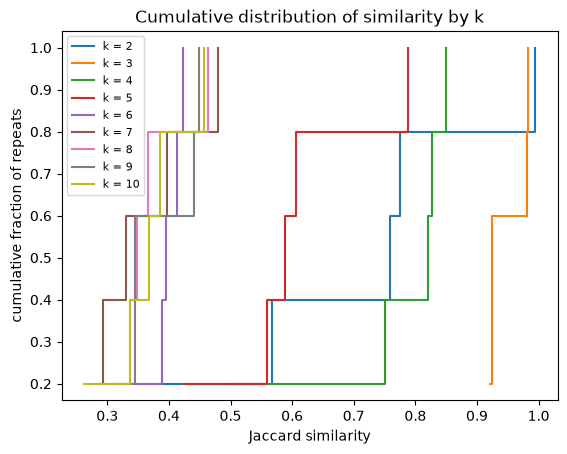

In [27]:
for col in S.columns:
    values = np.sort(S[col].to_numpy())
    plt.step(values, np.arange(1, len(values) + 1) / len(values), where="post", label=f"k = {col}")
plt.xlabel("Jaccard similarity")
plt.ylabel("cumulative fraction of repeats")
plt.title("Cumulative distribution of similarity by k")
plt.legend(fontsize=8)
plt.show()